# Linear Regression for Telescope Calibration

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 4 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://tingyuansen.github.io/statml/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

Before any scientific analysis, we must understand and correct the systematic effects in our measurements. The atmospheric conditions change during the night, telescopes flex as they track the sky, and optical components expand with the temperature. Uncorrected, these effects can exceed the signals that we want to measure.

This tutorial studies calibration with radial velocity (RV) measurements. The RV method finds planets through the tiny wobbles that they cause in the velocity of their host stars. We observe RV standard stars, whose velocities stay stable for decades, under different conditions. The observations contain systematic errors that correlate with recorded metadata, such as the temperature and the position of the telescope.

The calibration shows how linear regression estimates a quantity of physical interest together with nuisance effects. The tools are design matrices, maximum likelihood estimation, the bootstrap and weighted least squares. We go from the calibration of one telescope to a network of telescopes.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- The linear regression model and its assumptions
- Maximum likelihood estimation and its analytical solution
- Design matrices, which hold the features of a regression problem
- Bootstrap methods, which use resampling to estimate parameter uncertainties
- Python programming with NumPy arrays and matplotlib plots

### Learning Objectives

After this tutorial you can do the following.

- Formulate an instrumental calibration as a linear regression, where the systematic effects depend on observable metadata
- Estimate astrophysical parameters and calibration coefficients together
- Use weighted least squares when the measurements have different uncertainties, as is common in astronomy
- Design and solve a regression with several types of parameters, here stellar properties and telescope systematic effects
- Combine the observations of several instruments to strengthen the calibration of a telescope network

We begin by importing the libraries and setting the plot style.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Color maps of the book, white to a palette color to its dark shade, and blue-white-red
book_maps = [('book_blue', 'w', 'C0', '#172F4C'), ('book_green', 'w', 'C2', '#153F32'),
             ('book_orange', 'w', 'C1', '#724D1D'), ('book_div', 'C0', 'w', 'C3'),
             ('book_grey', 'w', '#9E9E9E', '#222222')]
for name, *colors in book_maps:
    plt.colormaps.register(LinearSegmentedColormap.from_list(name, colors), force=True)

# Fix the random seed
np.random.seed(42)

## From Telescope Systematics to Linear Models

Consider a single RV measurement of a standard star, a star with a constant true velocity $y_{\text{true}}$. The observed RV $t$ differs from this true value because of effects that come from the instrument and from the observing conditions

$$t = y_{\text{true}} + \sum_{j=1}^{4} w_j x_j + \varepsilon.$$

Here $x_j$ is the $j$th item of the metadata that describe the observing conditions. These are quantities that we can measure or record at the time of the observation. The coefficient $w_j$ says how much the $j$th item affects our measurement, and $\varepsilon$ is random measurement noise.

In this example we assume that four recorded conditions influence the measurements. A real instrument can record many more metadata.

1. **Zenith angle.** The angle of the star from the vertical. At a larger angle the light crosses more atmosphere, and the atmospheric dispersion can bias the velocity.
2. **Temperature.** Thermal expansion of the optics can shift the spectral lines on the detector.
3. **Humidity.** It changes the refractive index of the air and so the optical path.
4. **Instrumental drift.** Flexure and detector instabilities cause velocity offsets that change during the night.

The linear model is simple and easy to interpret. Once we know the coefficients $w_j$, we can correct any observation with recorded metadata. When we scale the effects to the same unit, they also show which effects dominate our error budget.

We now generate synthetic data that mimic these systematic effects. For simplicity, the zenith angle of each observation is random and does not follow the track of a star.

In [2]:
def generate_telescope_data(N=100, seed=42):
    """Generate synthetic RV data with systematic effects and no noise."""
    np.random.seed(seed)  # fix the seed so that the data are reproducible

    # Metadata matrix with one row per observation
    X = np.zeros((N, 4))

    # Feature 1 is the zenith angle in degrees
    # A higher angle means more atmosphere and a stronger dispersion effect
    X[:, 0] = np.random.uniform(0, 60, N)  # random angle for each observation

    # Feature 2 is the temperature in degrees Celsius
    # It follows a cosine during the night, with random fluctuations
    time = np.linspace(0, 8, N)  # 8-hour observing night
    X[:, 1] = 20 + 5 * np.cos(2*np.pi*time/8) + np.random.normal(0, 0.5, N)

    # Feature 3 is the humidity in percent
    # It varies around 50 percent with a large scatter
    X[:, 2] = 50 + 10*np.random.randn(N)

    # Feature 4 is the time-dependent instrumental drift
    # It is linear in time, with small random variations
    X[:, 3] = np.linspace(0, 1, N) + 0.1*np.random.randn(N)

    # True RV of our simulated standard star
    y_true = -15.0  # km/s

    # True coefficients, which say how each parameter affects the RV
    # We chose these values for this example
    w_true = np.array([
        0.05,   # zenith angle, in km/s per degree
        0.02,   # temperature, in km/s per °C
        0.01,   # humidity, in km/s per %
        0.5     # drift, in km/s over the night
    ])

    # Generate clean velocities (systematic effects but no noise)
    y_clean = y_true + X @ w_true  # matrix-vector product

    return X, y_clean, y_true, w_true, time

# Generate example data
X, y_clean, y_true, w_true, time = generate_telescope_data(N=100)

The synthetic velocities contain the systematic effects but no noise. Real observations also contain random errors from photon statistics and detector readout. We add Gaussian noise with a standard deviation of 0.1 km/s.

True RV of the standard star = -15.00 km/s
Mean observed RV = -12.40 km/s
RV standard deviation = 0.89 km/s


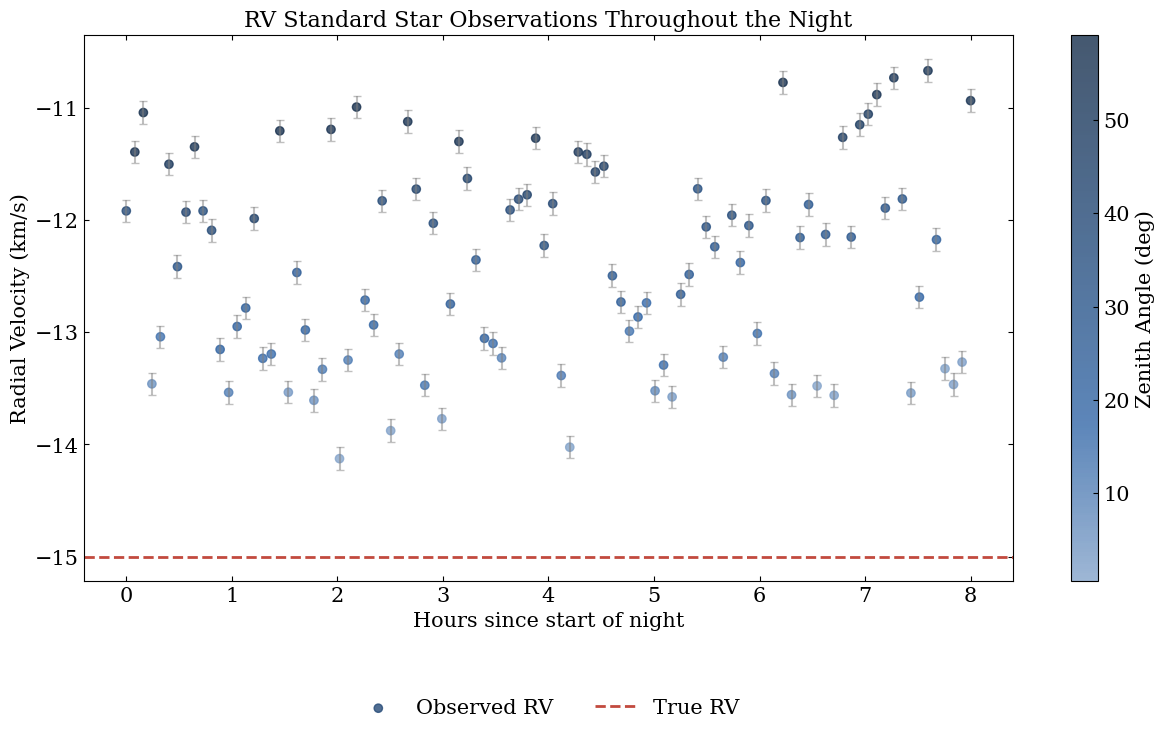

In [3]:
# Simulate the observations of one telescope with the systematic effects of the previous cell
X, y_clean, true_rv, w_true, time = generate_telescope_data(N=100, seed=87)

# Add homogeneous photon noise
noise_level = 0.1  # km/s
y_noisy = y_clean + np.random.normal(0, noise_level, len(y_clean))  # Gaussian noise

# Print a summary of the dataset
print(f"True RV of the standard star = {true_rv:.2f} km/s")
print(f"Mean observed RV = {np.mean(y_noisy):.2f} km/s")
print(f"RV standard deviation = {np.std(y_noisy):.2f} km/s")

# Visualize the observations over time
plt.figure(figsize=(12.8, 7.7))

# Plot the observations with error bars, colored by the zenith angle (the blue map without its white end)
plt.errorbar(time, y_noisy, yerr=0.1, fmt='none', ecolor='gray', alpha=0.5, capsize=3)
points = plt.scatter(time, y_noisy, c=X[:, 0], cmap=plt.matplotlib.colors.ListedColormap(plt.colormaps['book_blue'](np.linspace(0.3, 1, 256))),
                     alpha=0.8, label='Observed RV')
plt.colorbar(points, label='Zenith Angle (deg)')

# Show the true RV
plt.axhline(true_rv, color='C3', linestyle='--', linewidth=2,
            label='True RV')

# Labels and formatting
plt.xlabel('Hours since start of night')
plt.ylabel('Radial Velocity (km/s)')
plt.title('RV Standard Star Observations Throughout the Night')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)

plt.tight_layout()
plt.show()

This time series shows how important the calibration is. The observed velocities scatter around values that differ a lot from the true RV (red dashed line). The variations far exceed our measurement precision of 0.1 km/s. The systematic offset of about 2.6 km/s and the additional scatter of about 0.9 km/s make uncalibrated observations unfit for precise RV work.

The color shows the zenith angle, and the velocity rises with it. The instrumental drift is part of the data too, but the larger effects hide it in this plot. The task of the calibration is to separate all these overlapping effects with the recorded metadata.

## Calibrating a Single Telescope

With our dataset in hand, we turn to the calibration problem itself. We need to solve for two types of unknowns at the same time.

1. **The true RV of our standard star** ($y_{\text{true}}$)
2. **The calibration coefficients** ($w_1, \ldots, w_4$) that relate the metadata to the systematic offsets

In a typical regression we know the true value of what we want to predict. Here the true RV of the star is unknown, and we must infer it from the data. The linear structure of the problem lets us solve for all parameters together with an augmented design matrix.

The next step is to rewrite our model

$$t = y_{\text{true}} + \sum_{j=1}^{4} w_j x_j + \varepsilon$$

as a standard linear regression. As in Section 4.2, we add a constant feature to the metadata and absorb $y_{\text{true}}$ into the weight vector as the intercept $w_0$

$$t = \mathbf{w}^T\boldsymbol{\phi}(\mathbf{x}) + \varepsilon,$$

where $\boldsymbol{\phi}(\mathbf{x}) = (1, x_1, x_2, x_3, x_4)^T$ and $\mathbf{w} = (y_{\text{true}}, w_1, w_2, w_3, w_4)^T$. The design matrix $\boldsymbol{\Phi}$ has one row $\boldsymbol{\phi}(\mathbf{x}_i)^T$ for each observation $i$, so it has a column of ones. The maximum likelihood solution then follows from our standard linear regression machinery.

In [4]:
# Shuffled indices for a random train-test split
n_obs = len(y_noisy)
idx = np.arange(n_obs)
np.random.shuffle(idx)

# Split the data, 80 percent for training and 20 percent for testing
n_train = int(0.8 * n_obs)
train_idx = idx[:n_train]
test_idx = idx[n_train:]
y_train = y_noisy[train_idx]
y_test = y_noisy[test_idx]
time_test = time[test_idx]

# Augment the design matrices with a column of ones
# This lets us estimate y_true as a regression coefficient
X_train = np.column_stack([np.ones(len(train_idx)), X[train_idx]])
X_test = np.column_stack([np.ones(len(test_idx)), X[test_idx]])

print(f"Data split = {len(train_idx)} training, {len(test_idx)} test observations")


Data split = 80 training, 20 test observations


### Maximum Likelihood Solution

With our augmented design matrix in place, finding the calibration parameters becomes a standard linear regression problem. For Gaussian noise with a constant variance $\sigma^2$, the maximum likelihood solution is the ordinary least squares solution (Section 4.4)

$$\mathbf{w}_{\text{ML}} = (\boldsymbol{\Phi}^T\boldsymbol{\Phi})^{-1}\boldsymbol{\Phi}^T\mathbf{t},$$

where $\mathbf{t}$ is the vector of observed RVs. The vector $\mathbf{w}_{\text{ML}}$ contains our estimate of the true RV and the calibration coefficients.

This formulation uses the linear algebra of Chapter 4. The augmented design matrix treats all unknowns in the same way. The mathematics is the same whether we estimate an astrophysical parameter or an instrumental systematic effect.

We now implement this solution and examine what it tells us about the systematic effects of our telescope.

In [5]:
# Maximum likelihood solution w = (Φ^T Φ)^{-1} Φ^T t
# We solve (Φ^T Φ) w = Φ^T t without forming the inverse
XTX = X_train.T @ X_train
XTy = X_train.T @ y_train
w_full = np.linalg.solve(XTX, XTy)  # solve the linear system

# The first element is y_true, the others are the calibration coefficients
y_true_est = w_full[0]
w_est = w_full[1:]

# Display the results
print(f"Estimated true RV = {y_true_est:.3f} km/s")
print(f"True RV (simulated) = {true_rv:.3f} km/s")
print(f"Difference = {y_true_est - true_rv:.3f} km/s")

# Print the calibration coefficients with their true values
feature_names = ['Zenith angle', 'Temperature', 'Humidity', 'Instrumental drift']
units = ['km/s per degree', 'km/s per °C', 'km/s per %', 'km/s per unit']

print()
for name, unit, w_j, w_true_j in zip(feature_names, units, w_est, w_true):
    print(f"{name:20s} = {w_j:.3f} (true value {w_true_j:.3f}) {unit}")


Estimated true RV = -15.006 km/s
True RV (simulated) = -15.000 km/s
Difference = -0.006 km/s

Zenith angle         = 0.050 (true value 0.050) km/s per degree
Temperature          = 0.022 (true value 0.020) km/s per °C
Humidity             = 0.009 (true value 0.010) km/s per %
Instrumental drift   = 0.520 (true value 0.500) km/s per unit


We now check the calibration. We compute the predictions and the residuals before and after the fit, and we measure their scatter with the root mean square (RMS).

In [6]:
# Calculate the predictions, which are matrix-vector products
y_train_pred = X_train @ w_full
y_test_pred = X_test @ w_full

# Before the calibration we use the mean as a naive estimate
train_residuals_before = y_train - np.mean(y_train)
test_residuals_before = y_test - np.mean(y_test)

# Calculate the residuals after the calibration
train_residuals_after = y_train - y_train_pred
test_residuals_after = y_test - y_test_pred

# Print the RMS scatter of the velocities
print("RMS velocity scatter")
print(f"Training set before calibration = {np.std(train_residuals_before):.3f} km/s")
print(f"Training set after calibration = {np.std(train_residuals_after):.3f} km/s")
print(f"Test set before calibration = {np.std(test_residuals_before):.3f} km/s")
print(f"Test set after calibration = {np.std(test_residuals_after):.3f} km/s")
print(f"Photon noise limit = 0.100 km/s")


RMS velocity scatter
Training set before calibration = 0.892 km/s
Training set after calibration = 0.103 km/s
Test set before calibration = 0.868 km/s
Test set after calibration = 0.099 km/s
Photon noise limit = 0.100 km/s


### Parameter Importance

We now ask which systematic effects contribute most to the error budget. A direct comparison of the coefficients can mislead, because the metadata have different units and scales. A coefficient of 0.05 km/s per degree can be a larger or a smaller effect than 0.5 km/s per unit of drift. It depends on how much each parameter varies.

To compare the effects, we scale each coefficient with the standard deviation of its metadata, $w_j \operatorname{std}(x_j)$. This is the typical RV change that one standard deviation of parameter $j$ causes. It has the unit km/s for all parameters, so we can compare the contributions directly. It shows which effects need the most attention in the design of the instrument and the planning of observations. The figure below shows the test residuals before and after the calibration on the left and this normalized importance on the right.


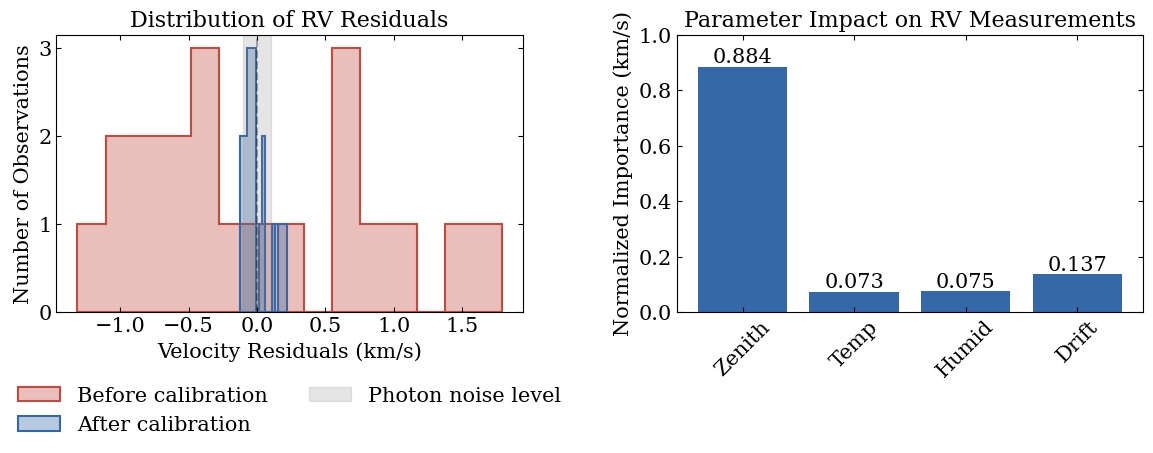

In [7]:
# Plot the residuals before and after the calibration and the normalized parameter importance
plt.figure(figsize=(12, 5))

# Plot 1 shows the histogram of the test residuals
plt.subplot(121)
plt.hist(test_residuals_before, bins=15, label='Before calibration',
         histtype='stepfilled', facecolor=('C3', 0.35), edgecolor='C3', linewidth=1.5)
plt.hist(test_residuals_after, bins=15, label='After calibration',
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
plt.axvline(0, color='k', linestyle='--', alpha=0.3)

# Add the photon noise reference
plt.axvspan(-0.1, 0.1, color='grey', alpha=0.2,
            label='Photon noise level')

# Labels and title
plt.xlabel('Velocity Residuals (km/s)')
plt.ylabel('Number of Observations')
plt.title('Distribution of RV Residuals')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=2)

# Plot 2 shows the normalized parameter importance
plt.subplot(122)
param_names = ['Zenith', 'Temp', 'Humid', 'Drift']

# Standard deviation of each metadata item over the test data
# Remove the first column (ones) to get the original features
X_test_features = X_test[:, 1:]
param_stds = np.std(X_test_features, axis=0)

# Normalized importance, the coefficient times the standard deviation
normalized_importance = np.abs(w_est) * param_stds

# Bar plot with the value above each bar
bars = plt.bar(param_names, normalized_importance)
plt.ylabel('Normalized Importance (km/s)')
plt.title('Parameter Impact on RV Measurements')
plt.xticks(rotation=45)
for bar, val in zip(bars, normalized_importance):
    plt.text(bar.get_x() + bar.get_width()/2., bar.get_height(),
             f'{val:.3f}', ha='center', va='bottom')
plt.ylim(0, 1.)

plt.tight_layout()
plt.show()


### Results from Single-Telescope Calibration

Our calibration analysis gives three main results.

1. **Successful systematic correction.** We reduced the RMS scatter from about 0.9 km/s to about 0.1 km/s, which is close to the photon noise limit. This improvement of nearly an order of magnitude turns unusable data into data that science can use.
2. **Accurate parameter estimates.** The estimated true RV differs from the true value by only 0.006 km/s. The calibration coefficients match their true values closely, so the joint estimation of all parameters works.
3. **Dominant systematic effect.** The normalized importance shows that the zenith angle dominates our error budget, and the drift comes second. Careful scheduling of observations at small zenith angles, and then mechanical stability, would improve future measurements most.

This single-telescope calibration shows that linear regression can correct systematic errors.

## Statistical Power and Sample Size

Our analysis used 100 observations for a good calibration. We now ask how many observations we need. The relation between the sample size and the parameter uncertainty matters for an efficient scheduling of the telescope. Too few observations give a poor calibration. Too many observations waste telescope time that we can use for science targets.

The bootstrap lets us explore this trade-off (Section 3.7). We resample our data with replacement, which gives the uncertainty of the recovered RV. We then see how this uncertainty scales with the number of observations. For each number we simulate 20 datasets and average their uncertainties, because the uncertainty also depends on the particular values of the metadata.

In [8]:
# Number of observations to test, bootstrap samples and simulated datasets for each number
N_values = [50, 100, 200, 400, 800]
n_bootstrap = 1000
n_datasets = 20

scaling_results = []
for N in N_values:
    y_true_stds = []  # bootstrap uncertainty of each dataset

    for k in range(n_datasets):
        # Generate a new dataset of N observations, with its own random seed
        X_N, y_clean_N, *_ = generate_telescope_data(N=N, seed=k)
        y_noisy_N = y_clean_N + np.random.normal(0, 0.1, N)  # add Gaussian noise

        # Augment the design matrix once
        X_aug = np.column_stack([np.ones(N), X_N])

        # Storage for the bootstrap results
        y_true_boot = np.zeros(n_bootstrap)

        # Perform the bootstrap
        for i in range(n_bootstrap):
            # Bootstrap sample, drawn with replacement
            idx = np.random.choice(N, size=N, replace=True)
            X_boot = X_aug[idx]
            y_boot = y_noisy_N[idx]

            # Fit the model to the bootstrap sample
            try:
                w_full = np.linalg.solve(X_boot.T @ X_boot, X_boot.T @ y_boot)  # normal equations
                y_true_boot[i] = w_full[0]  # extract the RV estimate
            except np.linalg.LinAlgError:
                # A bootstrap sample can give a singular matrix
                y_true_boot[i] = np.nan

        # Remove any failed fits
        y_true_boot = y_true_boot[~np.isnan(y_true_boot)]

        # The uncertainty of this dataset is the standard deviation of its bootstrap distribution
        y_true_stds.append(np.std(y_true_boot))

        # Keep the bootstrap distribution of the first dataset with N=100
        if N == 100 and k == 0:
            y_true_dist = y_true_boot

    # Store the results of this sample size, averaged over the datasets
    scaling_results.append({
        'N': N,
        'y_true_std': np.mean(y_true_stds),
        'y_true_dist': y_true_dist if N == 100 else None
    })



We plot the bootstrap distribution of the RV for one dataset with $N = 100$, and the uncertainty against the number of observations.

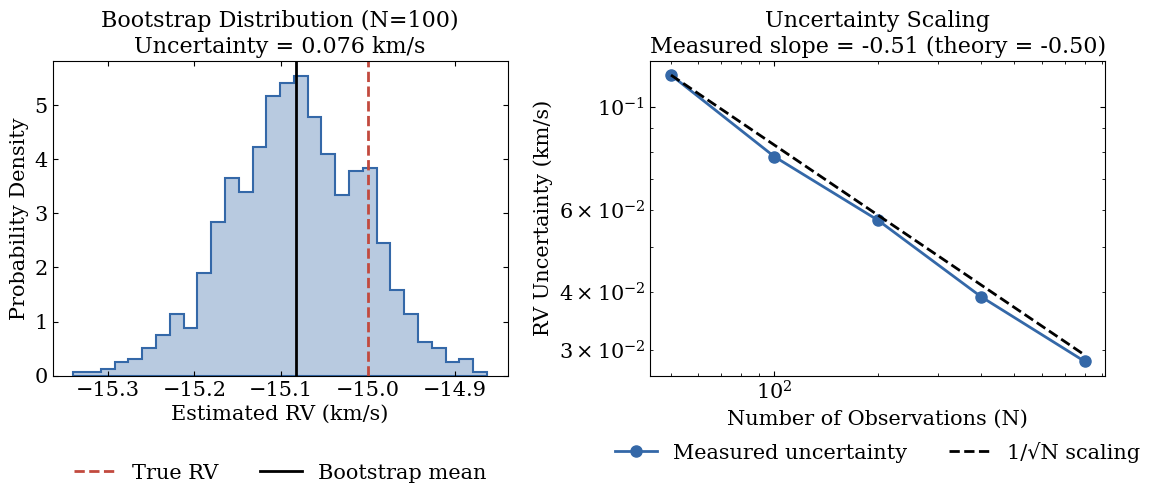

In [9]:
# Create the visualization of the bootstrap results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.5))

# Plot 1 shows the bootstrap distribution for N=100
# The first result with N = 100
N100_result = next(r for r in scaling_results if r['N'] == 100)
ax1.hist(N100_result['y_true_dist'], bins=30, density=True,
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
ax1.axvline(-15, color='C3', linestyle='--', linewidth=2, label='True RV')
ax1.axvline(np.mean(N100_result['y_true_dist']), color='k', linestyle='-',
            linewidth=2, label='Bootstrap mean')
ax1.set_xlabel('Estimated RV (km/s)')
ax1.set_ylabel('Probability Density')
ax1.set_title(f"Bootstrap Distribution (N=100)\nUncertainty = {np.std(N100_result['y_true_dist']):.3f} km/s")
ax1.legend(loc='upper center', bbox_to_anchor=(0.5, -0.22), ncol=2)

# Plot 2 shows the scaling with the sample size
N_values = [r['N'] for r in scaling_results]
y_true_stds = [r['y_true_std'] for r in scaling_results]

# Plot the measured uncertainties
ax2.loglog(N_values, y_true_stds, 'o-', markersize=8, linewidth=2,
           label='Measured uncertainty')

# Add the theoretical 1/√N scaling through the first point
N_array = np.array(N_values)
theoretical = y_true_stds[0] * np.sqrt(N_values[0]/N_array)
ax2.loglog(N_array, theoretical, '--', color='k', linewidth=2, label='1/√N scaling')

# Fit a power law to verify the scaling
log_N = np.log(N_values)
log_std = np.log(y_true_stds)
slope = np.polyfit(log_N, log_std, 1)[0]  # straight line in log-log space

# Labels, title and legend
ax2.set_xlabel('Number of Observations (N)')
ax2.set_ylabel('RV Uncertainty (km/s)')
ax2.set_title(f'Uncertainty Scaling\nMeasured slope = {slope:.2f} (theory = -0.50)')
ax2.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

plt.tight_layout()
plt.show()


### Results from Bootstrap Analysis

The bootstrap analysis shows that the uncertainty of the fitted RV follows the classical scaling law. The left panel shows the distribution of the RV estimates from 1000 bootstrap samples of one dataset with $N = 100$ observations. The distribution is approximately Gaussian, and its width is the uncertainty of the fitted RV. It is centered on the fit to the sample, so it shows the spread of the estimate and not its offset from the true RV.

The right panel shows the effect of a larger sample, with the uncertainty averaged over the 20 datasets of each size. The measured scaling exponent of about $-0.5$ is close to the theoretical prediction, which confirms that the uncertainty decreases as $1/\sqrt{N}$. This has practical consequences.

- **Smaller gains.** An increase from 50 to 100 observations gives a large improvement, but an increase from 400 to 800 observations gives much smaller gains. This suggests a balance between the telescope time and the precision.
- **Precision requirements.** If our science needs a precision of 0.05 km/s, the right panel shows that we need 200 to 400 observations. This helps us to plan the telescope time.

## Calibration with Variable Measurement Uncertainties

So far we have assumed that all observations have the same measurement uncertainty ($\sigma = 0.1$ km/s). This homoscedastic noise assumption rarely holds in practice. Real observations suffer from changing conditions, such as the seeing, clouds and instrumental problems. These conditions cause heteroscedastic uncertainties, which differ from one observation to the next.

When the measurement uncertainties vary, our calibration strategy must adapt. Observations with small uncertainties should carry more weight in the calibration, and noisy measurements should carry less. This leads to weighted least squares, in which the influence of an observation is inversely proportional to its variance (Section 4.3). We now examine how variable uncertainties appear in realistic data.

In [10]:
# Generate the clean data first
X, y_clean, y_true, w_true, time = generate_telescope_data(N=100)

np.random.seed(42)  # fix the seed so that the data are reproducible
N = len(y_clean)

# Generate variable uncertainties from a lognormal distribution, whose logarithm is Gaussian
# Most observations have good conditions, with uncertainties of 0.1 to 0.5 km/s
# Some have poor conditions, with larger uncertainties
sigma = np.random.lognormal(mean=-1.5, sigma=1.0, size=N)
sigma = np.clip(sigma, 0.1, 5.0)  # limit the uncertainties to 0.1 to 5 km/s

# Add noise scaled by the uncertainty of each measurement
noise = np.random.normal(0, 1, N) * sigma
y_noisy_var = y_clean + noise



We plot the measurements with their uncertainties as error bars.

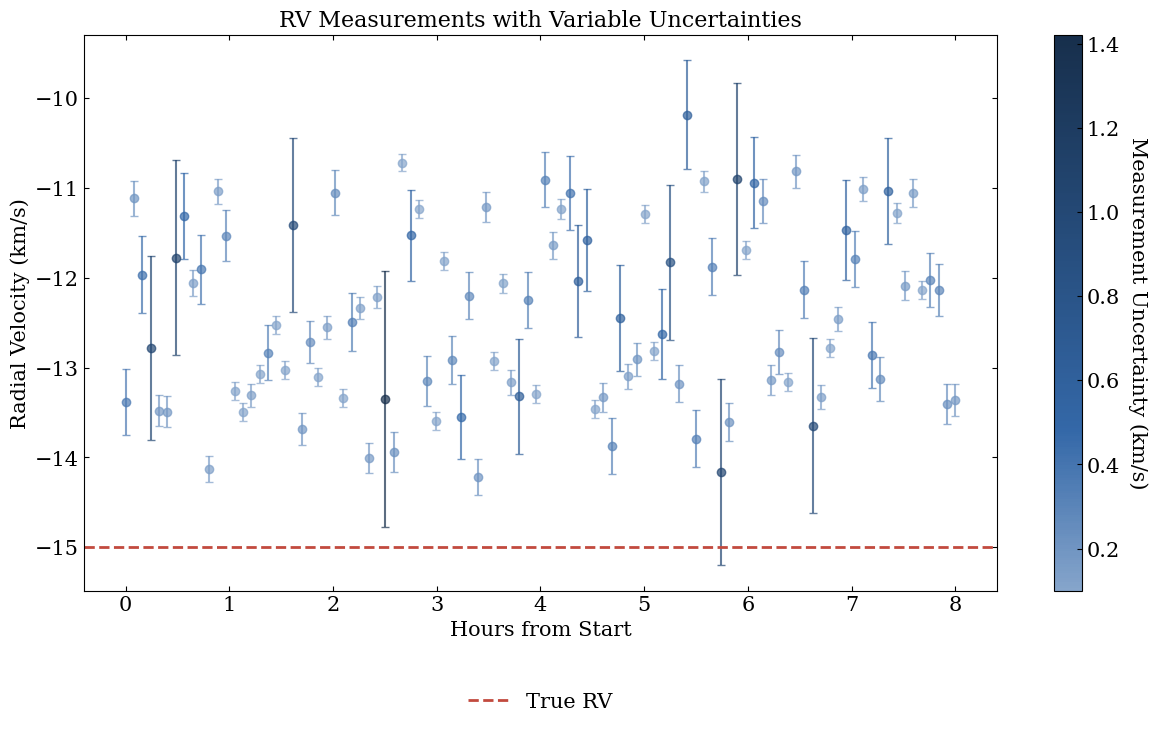

In [11]:
# Visualize the varying measurement uncertainties
fig, ax = plt.subplots(figsize=(12.6, 7.6))

# Color of each point from its uncertainty (the blue map without its white end), with the scale of the colorbar
noise_cmap = plt.matplotlib.colors.ListedColormap(plt.colormaps['book_blue'](np.linspace(0.3, 1, 256)))
colors = noise_cmap((sigma - sigma.min()) / (sigma.max() - sigma.min()))

# Plot the error bars, colored by the uncertainty
for i in range(len(time)):
    ax.errorbar(time[i], y_noisy_var[i], yerr=sigma[i],
                fmt='o', color=colors[i], alpha=0.7, capsize=3)

# Add the true RV line
ax.axhline(y_true, color='C3', linestyle='--', linewidth=2, label='True RV')

# Add the colorbar
sm = plt.cm.ScalarMappable(cmap=noise_cmap,
                           norm=plt.Normalize(vmin=sigma.min(), vmax=sigma.max()))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label('Measurement Uncertainty (km/s)', rotation=270, labelpad=20)

# Labels, title and legend
ax.set_xlabel('Hours from Start')
ax.set_ylabel('Radial Velocity (km/s)')
ax.set_title('RV Measurements with Variable Uncertainties')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.tight_layout()
plt.show()

### Weighted Least Squares: Maximum Likelihood with Heteroscedastic Noise

The plot above shows the problem. Some observations (the darker points) have uncertainties about ten times larger than our best measurements, or more. These observations should not influence the calibration as much as the precise ones. Weighted least squares gives a principled solution.

When the measurement uncertainties vary, the likelihood of $N$ independent observations is

$$p(\mathbf{t}|\mathbf{X}, \mathbf{w}, \{\sigma_i^2\}) = \prod_{i=1}^{N} \frac{1}{\sqrt{2\pi\sigma_i^2}} \exp\left(-\frac{(t_i - \mathbf{w}^T\boldsymbol{\phi}(\mathbf{x}_i))^2}{2\sigma_i^2}\right),$$

where each observation $i$ has its own uncertainty $\sigma_i$. Minus twice the logarithm of the likelihood, without the constants, gives the weighted least squares objective

$$\chi^2 = \sum_{i=1}^{N} \frac{(t_i - \mathbf{w}^T\boldsymbol{\phi}(\mathbf{x}_i))^2}{\sigma_i^2}.$$

Each observation has the data weight $\omega_i = 1/\sigma_i^2$, which differs from the model weights $\mathbf{w}$. Observations with small uncertainties (small $\sigma_i$) get large weights, and noisy observations contribute less to the total $\chi^2$. This is what we want, because precise measurements should dominate our calibration.

In matrix form, we write

$$\chi^2 = (\mathbf{t} - \boldsymbol{\Phi}\mathbf{w})^T \mathbf{S}^{-1} (\mathbf{t} - \boldsymbol{\Phi}\mathbf{w}),$$

where $\mathbf{S} = \text{diag}(\sigma_1^2, \sigma_2^2, \ldots, \sigma_N^2)$ is the diagonal matrix of the measurement variances. The maximum likelihood solution is

$$\mathbf{w}_{\text{ML}} = (\boldsymbol{\Phi}^T\mathbf{S}^{-1}\boldsymbol{\Phi})^{-1}\boldsymbol{\Phi}^T\mathbf{S}^{-1}\mathbf{t}.$$

This weighted solution generalizes our previous result. When all $\sigma_i$ are equal, $\mathbf{S}^{-1}$ is a scalar multiple of the identity matrix $\mathrm{Id}$, and we recover ordinary least squares. With varying uncertainties, the weight matrix $\mathbf{S}^{-1}$ makes each observation contribute according to its precision.

We now implement this weighted calibration and compare it with an unweighted approach.

In [12]:
# Augment the design matrix with a column of ones
X_aug = np.column_stack([np.ones(N), X])

# Weighted least squares solution
# The inverse weight matrix is S^{-1} = diag(1/sigma_i^2)
S_inv = np.diag(1 / sigma**2)  # diagonal matrix of weights

# Compute (Φ^T S^{-1} Φ)^{-1} Φ^T S^{-1} t
XTS_inv_X = X_aug.T @ S_inv @ X_aug  # matrix product
XTS_inv_y = X_aug.T @ S_inv @ y_noisy_var  # matrix product
w_weighted = np.linalg.solve(XTS_inv_X, XTS_inv_y)  # solve the linear system

# Unweighted least squares, which ignores the uncertainties
XTX = X_aug.T @ X_aug  # matrix product
XTy = X_aug.T @ y_noisy_var  # matrix product
w_unweighted = np.linalg.solve(XTX, XTy)  # solve the linear system

# Display the results
print(f"{'Parameter':15s} {'True':>8s} {'Weighted':>10s} {'Unweighted':>11s} {'Weighted Error':>15s}")
print("-" * 60)

# True RV
print(f"{'RV (km/s)':15s} {y_true:8.3f} {w_weighted[0]:10.3f} {w_unweighted[0]:11.3f} {abs(w_weighted[0]-y_true):15.3f}")

# Calibration coefficients
param_names = ['Zenith (deg)', 'Temp (°C)', 'Humidity (%)', 'Drift']
for i in range(4):
    print(f"{param_names[i]:15s} {w_true[i]:8.3f} {w_weighted[i+1]:10.3f} {w_unweighted[i+1]:11.3f} {abs(w_weighted[i+1]-w_true[i]):15.3f}")

# Calculate the total parameter error
weighted_error = np.sqrt(np.mean((w_weighted[0] - y_true)**2 +
                                 (w_weighted[1:] - w_true)**2))
unweighted_error = np.sqrt(np.mean((w_unweighted[0] - y_true)**2 +
                                   (w_unweighted[1:] - w_true)**2))

# Print the total parameter error
print(f"\nTotal RMS parameter error")
print(f" Weighted = {weighted_error:.3f}")
print(f" Unweighted = {unweighted_error:.3f}")
print(f" Improvement factor = {unweighted_error/weighted_error:.1f}x")

Parameter           True   Weighted  Unweighted  Weighted Error
------------------------------------------------------------
RV (km/s)        -15.000    -14.895     -14.853           0.105
Zenith (deg)       0.050      0.050       0.050           0.000
Temp (°C)          0.020      0.017       0.023           0.003
Humidity (%)       0.010      0.009       0.006           0.001
Drift              0.500      0.496       0.455           0.004

Total RMS parameter error
 Weighted = 0.105
 Unweighted = 0.148
 Improvement factor = 1.4x


The comparison shows that weighted least squares gives estimates closer to the true values for the RV, the humidity and the drift. The zenith angle and the temperature are about equally close. The overall improvement factor of 1.4x is modest in this example.

In real astronomical applications, the benefit of proper weighting becomes larger in the following cases.

- We combine data from different instruments with very different precisions.
- We include observations taken under highly variable conditions.
- We work near the precision limits, where small improvements matter.

## Multi-telescope Network Calibration

A network of telescopes observes the same standard stars. Each telescope has its own systematic effects, for example its own temperature coefficient, but the true velocity of each star is constant. This gives an opportunity for cross-calibration. For a network that observes several standard stars, each measurement depends on the following.

- Which star we observed, which sets the true RV
- Which telescope made the observation, which sets the systematic effects
- The metadata at the time of the observation

We model each observation $i$ as

$$t_i = y_{\text{true},s(i)} + \mathbf{x}_i^T\mathbf{w}_{k(i)} + \varepsilon_i,$$

where $s(i)$ is the star of observation $i$ and $k(i)$ is the telescope that made it. The vector $\mathbf{w}_{k(i)}$ is the response of that telescope to the metadata.

This formulation describes the structure of the network. Each telescope keeps its own calibration coefficients, and all observations share the stellar RVs. We must construct a design matrix that encodes these relations.

We now explore this multi-telescope scenario with synthetic data for an observing campaign.

In [13]:
# Fix the random seed
np.random.seed(42)

# Network parameters
N_telescopes = 5
N_stars = 20
N_obs_per_star = 50
N_total = N_stars * N_obs_per_star

# Print the network configuration
print(f"Number of telescopes = {N_telescopes}")
print(f"Number of RV standard stars = {N_stars}")
print(f"Observations per star = {N_obs_per_star}")
print(f"Total observations = {N_total}")

# Generate the true stellar RVs
# RV standard stars span a range of velocities
rv_true = np.random.normal(0, 30, N_stars)  # km/s

# Generate the telescope calibration coefficients
# Each telescope responds differently to the same metadata
w_true = np.random.normal(0, 0.1, (N_telescopes, 4))

# Add some structure to make the telescopes more distinct
# Telescope 0 has its temperature coefficient multiplied by 3
w_true[0, 1] *= 3

# Telescope 1 has its zenith angle coefficient multiplied by 2
w_true[1, 0] *= 2

# Telescope 2 has its drift coefficient multiplied by 2
w_true[2, 3] *= 2

# Generate the metadata for each observation
X = np.random.normal(0, 1, (N_total, 4))

# Assign the observations to stars
# Each star gets exactly N_obs_per_star observations
star_idx = np.repeat(np.arange(N_stars), N_obs_per_star)  # each star index repeated 50 times

# Assign each observation to a random telescope
tel_idx = np.random.randint(0, N_telescopes, N_total)  # random telescope for each observation

# Generate the observed RVs
y_obs = np.zeros(N_total)
for i in range(N_total):
    # True RV of the star + telescope systematic effects + noise
    y_obs[i] = (rv_true[star_idx[i]] +
                X[i] @ w_true[tel_idx[i]] +  # metadata times the coefficients of this telescope
                np.random.normal(0, 0.1))  # noise of 0.1 km/s

# Store the network data
network_data = {
    'y_obs': y_obs,
    'X': X,
    'tel_idx': tel_idx,
    'star_idx': star_idx,
    'true_params': {
        'w': w_true,
        'rv': rv_true
    }
}


Number of telescopes = 5
Number of RV standard stars = 20
Observations per star = 50
Total observations = 1000


### Constructing the Design Matrix

The multi-telescope calibration problem needs a careful construction of the design matrix. In the single-telescope calibration we had one set of calibration coefficients. We now have the following parameters.

- $N_{\text{tel}} \times 4$ telescope calibration parameters, because each telescope has 4 metadata coefficients
- $N_{\text{stars}}$ stellar RV parameters

Our parameter vector is

$$\mathbf{w} = [\mathbf{w}_1^T, \mathbf{w}_2^T, \ldots, \mathbf{w}_{N_{\text{tel}}}^T, y_{\text{true},1}, y_{\text{true},2}, \ldots, y_{\text{true},N_{\text{stars}}}]^T.$$

For each observation $i$, we need a row of the design matrix $\boldsymbol{\Phi}$ that does the following.

1. It places the metadata $\mathbf{x}_i$ in the columns of telescope $k(i)$.
2. It places a 1 in the column of star $s(i)$.
3. It places 0 everywhere else.

Consider an example with 3 telescopes and 4 stars. Observation $i$ is star 2 observed by telescope 3, with metadata $\mathbf{x}_i = [x_1, x_2, x_3, x_4]$. The row of the design matrix is

$$\text{row } i \text{ of } \boldsymbol{\Phi} = [\underbrace{0,0,0,0}_{\text{tel 1}}, \underbrace{0,0,0,0}_{\text{tel 2}}, \underbrace{x_1,x_2,x_3,x_4}_{\text{tel 3}}, \underbrace{0,1,0,0}_{\text{stars}}].$$

This sparse structure shows which parameters affect each observation. Each observation depends on only 5 parameters, which are 4 telescope coefficients and 1 stellar RV. The full parameter vector can have hundreds of parameters.

Once we have constructed the matrix, we apply standard linear regression

$$\mathbf{w}_{\text{ML}} = (\boldsymbol{\Phi}^T\boldsymbol{\Phi})^{-1}\boldsymbol{\Phi}^T\mathbf{t}.$$

The solution gives all stellar RVs and all telescope calibration coefficients together, and it uses all observations of the network.

In [14]:
# Build the design matrix with 4 columns per telescope, then 1 column per star
N_metadata = X.shape[1]  # number of metadata items, 4

# Total columns, the telescope parameters plus the star RVs
N_cols = N_metadata * N_telescopes + N_stars

# Initialize the sparse design matrix
X_design = np.zeros((N_total, N_cols))

# Fill the design matrix row by row
for i in range(N_total):
    # Place the metadata in the columns of the telescope of this observation
    # The telescope parameters occupy the first N_metadata * N_telescopes columns
    start_col = tel_idx[i] * N_metadata
    X_design[i, start_col:start_col + N_metadata] = X[i]

    # Place a 1 in the column of the star of this observation
    # The star RVs occupy the last N_stars columns
    X_design[i, N_metadata * N_telescopes + star_idx[i]] = 1

# Print the shape of the design matrix
print(f"Design matrix shape = {X_design.shape}")

# Check the sparsity, the fraction of zero entries
sparsity = 1 - np.count_nonzero(X_design) / X_design.size
print(f"\nMatrix sparsity = {sparsity:.1%}")

# Solve the multi-telescope calibration problem
# Add a small regularization for numerical stability
lambda_reg = 1e-6
N_params = X_design.shape[1]
I_reg = lambda_reg * np.eye(N_params)  # identity matrix times a small number

# Solve the normal equations (Φ^T Φ + regularization) w = Φ^T t
XTX = X_design.T @ X_design
XTy = X_design.T @ network_data['y_obs']
beta_est = np.linalg.solve(XTX + I_reg, XTy)  # solve the linear system

# Extract the telescope and star parameters
w_est = beta_est[:4*N_telescopes].reshape(N_telescopes, 4)  # one row of 4 coefficients per telescope
rv_est = beta_est[4*N_telescopes:]


Design matrix shape = (1000, 40)

Matrix sparsity = 87.5%


We compare the estimated and the true coefficients and RVs in two plots, and we print the errors.

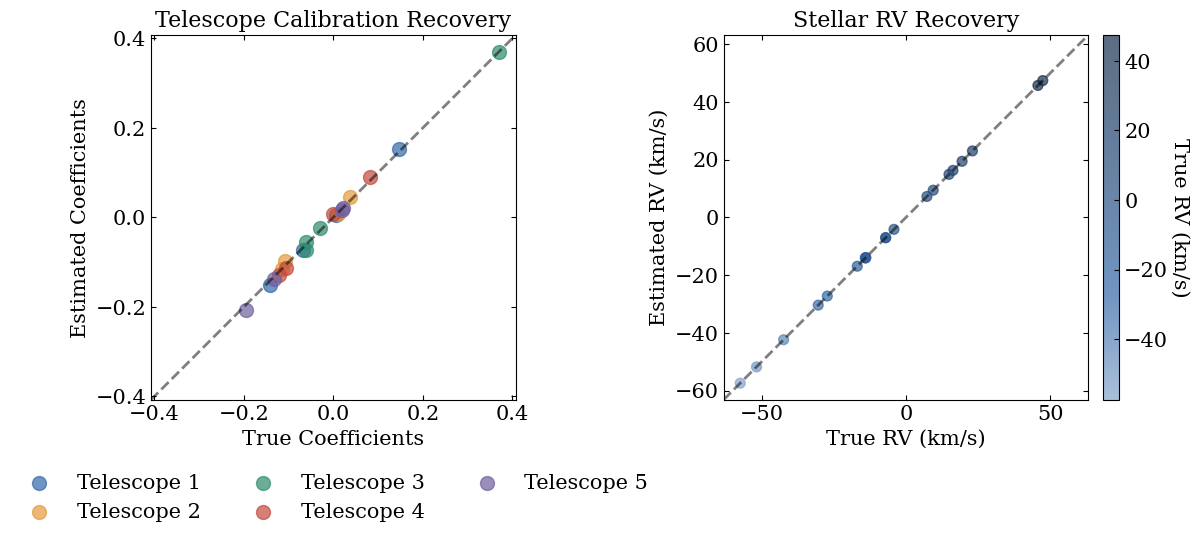

In [15]:
# Get the true parameters for comparison
w_true = network_data['true_params']['w']
rv_true = network_data['true_params']['rv']

# Create the visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot 1 compares the estimated and true telescope coefficients
ax = axes[0]
ax.set_box_aspect(1)  # square panels, so both panels have the same size

# Flatten the telescope coefficients for plotting
w_true_flat = w_true.flatten()
w_est_flat = w_est.flatten()

# Color the points by telescope, with the palette of the book
telescope_colors = [f'C{tel}' for tel in range(N_telescopes)]
for tel in range(N_telescopes):
    idx_start = tel * 4
    idx_end = (tel + 1) * 4
    ax.scatter(w_true_flat[idx_start:idx_end],
               w_est_flat[idx_start:idx_end],
               alpha=0.7, s=100,
               color=telescope_colors[tel],
               label=f'Telescope {tel+1}')

# Add the diagonal line
lim_w = max(abs(w_true_flat).max(), abs(w_est_flat).max()) * 1.1
ax.plot([-lim_w, lim_w], [-lim_w, lim_w], '--', color='k', alpha=0.5, linewidth=2)

# Labels, title, legend and limits
ax.set_xlabel('True Coefficients')
ax.set_ylabel('Estimated Coefficients')
ax.set_title('Telescope Calibration Recovery')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
ax.set_xlim(-lim_w, lim_w)
ax.set_ylim(-lim_w, lim_w)

# Plot 2 compares the estimated and true stellar RVs
ax = axes[1]
ax.set_box_aspect(1)

# Color the points by the RV value, with the blue map without its white end
scatter = ax.scatter(rv_true, rv_est, alpha=0.7, s=50,
                     c=rv_true, cmap=plt.matplotlib.colors.ListedColormap(plt.colormaps['book_blue'](np.linspace(0.3, 1, 256))))

# Add the diagonal line
lim_rv = max(abs(rv_true).max(), abs(rv_est).max()) * 1.1
ax.plot([-lim_rv, lim_rv], [-lim_rv, lim_rv], '--', color='k', alpha=0.5, linewidth=2)

# Labels, title and limits
ax.set_xlabel('True RV (km/s)')
ax.set_ylabel('Estimated RV (km/s)')
ax.set_title('Stellar RV Recovery')
ax.set_xlim(-lim_rv, lim_rv)
ax.set_ylim(-lim_rv, lim_rv)

# Add the colorbar in a strip beside the panel, with the height of the panel
cax = ax.inset_axes([1.04, 0, 0.045, 1])
cbar = fig.colorbar(scatter, cax=cax)
cbar.set_label('True RV (km/s)', rotation=270, labelpad=15)

plt.tight_layout()
plt.show()

We compute the RMS errors of the coefficients and of the stellar RVs, and we print them with the errors of each telescope.

In [16]:
# Compute the error metrics
w_rms = np.sqrt(np.mean((w_est - w_true)**2))
rv_rms = np.sqrt(np.mean((rv_est - rv_true)**2))

# Print the error metrics
print(f"Telescope coefficients, RMS error = {w_rms:.4f}")
print(f"Stellar RVs, RMS error = {rv_rms:.3f} km/s")

# Show the error of each telescope
print("\nPer-telescope coefficient errors (RMS)")
for tel in range(N_telescopes):
    tel_error = np.sqrt(np.mean((w_est[tel] - w_true[tel])**2))
    print(f" Telescope {tel+1} = {tel_error:.4f}")

Telescope coefficients, RMS error = 0.0071
Stellar RVs, RMS error = 0.014 km/s

Per-telescope coefficient errors (RMS)
 Telescope 1 = 0.0057
 Telescope 2 = 0.0076
 Telescope 3 = 0.0078
 Telescope 4 = 0.0077
 Telescope 5 = 0.0066


The results show that the multi-telescope calibration works. We recover both the telescope coefficients and the stellar RVs with good precision.

- **Telescope calibration.** In the left panel all telescope coefficients lie close to the diagonal, so they agree with the true values. We separated the systematic signature of each telescope from the stellar signals.
- **Stellar RVs.** The right panel confirms that we determined the true velocities of all 20 standard stars well. The typical errors are about 0.01 to 0.02 km/s, much smaller than the measurement noise of 0.1 km/s.

This precision comes from the cross-constraints of the network. Suppose that telescope 1 and telescope 3 both observe star 7. After we account for the systematic effects of each telescope, their measurements must agree on the true RV of the star. These overlapping constraints strengthen the whole solution.

The per-telescope errors show another result. All telescopes reach a similar calibration quality, although their systematic effects differ. This suggests that the network approach does not need identical instruments. Different telescopes can calibrate each other if they observe enough common targets.

## Summary

This tutorial showed how linear regression is a basic tool for the calibration of astronomical measurements, with radial velocity standard stars as the example. We went from observations with one telescope to networks of telescopes, and we saw how to model, understand and correct the systematic instrumental effects.

1. **Calibration as regression.** We turned the calibration into the estimation of several parameters together. Both the astrophysical quantities (the stellar RVs) and the instrumental systematic effects (the response of the telescopes to the metadata) became regression coefficients. The augmented design matrix handles this joint estimation.
2. **Maximum likelihood for different noise.** With homoscedastic uncertainties we used the standard least squares solution. With heteroscedastic noise, weighted least squares followed from maximum likelihood, so each observation contributes according to its precision.
3. **Statistical scaling and experimental design.** The bootstrap confirmed that the uncertainty of the fitted RV scales as $1/\sqrt{N}$. This gives quantitative guidance for the planning of observations.
4. **Design matrix construction.** The step from one telescope to many showed how the design matrix encodes the structure of the problem. The sparse block structure of the multi-telescope matrix records which parameters affect each observation.

The techniques apply to other systematic effects that depend on measurable quantities. Examples are the dimming of starlight at large zenith angles and the drift of the wavelength scale of spectra with the temperature. The mathematics stays the same from two small telescopes to a global network.
